# Qlang: compile Python expressions into quantum circuits

Write a condition in plain Python. Qlang builds an expression tree, optimizes it, compiles it into a quantum circuit, and searches for inputs that satisfy it.

**In this demo**

1. The pitch
2. ASTNode
3. Optimizer
4. Classical check
5. Gates
6. Quantum circuits
7. Oracle truth table
8. Grover search
9. Amplification
10. BBHT
11. QAOA search

## Setup

Run this cell first. It installs Qlang if it's missing, then loads everything the demo needs. Longer helper code, like the chart, is in `qlang.demo`.

In [1]:
import importlib.util
import sys
from pathlib import Path

if sys.version_info < (3, 14):
    raise RuntimeError("Select a Python 3.14 or newer kernel for this repository.")

# Prefer this checkout when running from the repository or examples folder.
roots = [Path.cwd(), *Path.cwd().parents]
repo = next((root for root in roots if (root / "src" / "qlang").is_dir()), None)
if repo is not None:
    sys.path.insert(0, str(repo / "src"))
if importlib.util.find_spec("qlang") is None:
    %pip install "qlang @ git+https://github.com/asherhe/qlang" "qiskit[visualization]>=2.0" matplotlib pylatexenc

from qiskit import QuantumCircuit
import qlang
from qlang import compile_oracle, evaluate, optimize_expr, print_ast, search, qaoa
from qlang.demo import PARAMS, find_solutions, fresh_variables, plot_amplification, print_truth_table, traced_search

# Reuse the adjacent graph/circuit helpers; no widget installation is needed.
helper_dir = next((candidate for root in roots
                   for candidate in (root, root / "examples")
                   if (candidate / "oracle_visuals.py").is_file()), None)
if helper_dir is None:
    raise FileNotFoundError("Keep oracle_visuals.py and live_ast_widgets.py beside this notebook.")
sys.path.insert(0, str(helper_dir))
from oracle_visuals import show_oracle, plot_oracle_phases, export_oracle_visuals


## 1. The pitch

Plain Python in, a quantum search out. `x` is a 3-bit number (0 to 7) and `y` is a 2-bit number (0 to 3).

In [2]:
x, y = fresh_variables()

search(PARAMS, x + y == 5)

{'x': 2, 'y': 3}

## 2. ASTNode

Python operators don't calculate anything here. They build an expression tree made of `ASTNode`s: `Bit` for true/false values and `UInt` for integers.

In [3]:
x, y = fresh_variables()

print_ast(x + y == 5)

└─<Bit op==>
  ├─<UInt op+ (4-bit)>
  │ ├─<UInt x (3-bit)>
  │ └─<UInt y (2-bit)>
  └─<UInt 5 (3-bit)>


## 3. Optimizer

Before compiling, Qlang rewrites the tree into operations that are cheap to build. Multiplying by 2 just moves bits one place left, so it needs no multiplier circuit.

In [4]:
x, y = fresh_variables()
pred = 2 * x == 6

print("Before:")
print_ast(pred)

print("\nAfter:")
print_ast(optimize_expr(pred))

Before:
└─<Bit op==>
  ├─<UInt op* (5-bit)>
  │ ├─<UInt x (3-bit)>
  │ └─<UInt 2 (2-bit)>
  └─<UInt 6 (3-bit)>

After:
└─<Bit op==>
  ├─<UInt 0 s0 s0 s0 0 (5-bit)>
  │ ├─<Bit 0>
  │ ├─<Bit <UInt x (3-bit)>[0]>
  │ │ └─<UInt x (3-bit)>
  │ ├─<Bit <UInt x (3-bit)>[1]>
  │ │ └─<UInt x (3-bit)>
  │ ├─<Bit <UInt x (3-bit)>[2]>
  │ │ └─<UInt x (3-bit)>
  │ └─<Bit 0>
  └─<UInt 6 (3-bit)>


## 4. Classical check

The same tree can also run on a normal computer. Trying every input gives us the correct answers to compare against.

In [5]:
x, y = fresh_variables()

find_solutions(x + y == 5)

[{'x': 2, 'y': 3}, {'x': 3, 'y': 2}, {'x': 4, 'y': 1}, {'x': 5, 'y': 0}]

## 5. Gates

Quantum circuits are built from gates. These five are the main ones Qlang uses:

| Gate | What it does |
|---|---|
| **H** | Puts a qubit into a superposition of 0 and 1 |
| **X** | Flips a qubit, like NOT |
| **Z** | Flips the sign of the 1 state, which is how the oracle marks solutions |
| **CX** | Flips the target if the control is 1, like XOR |
| **CCX** | Flips the target if both controls are 1, like AND |

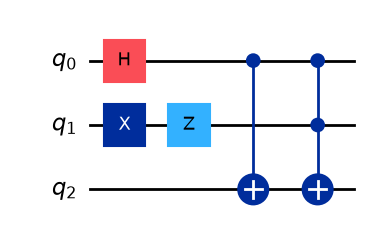

In [6]:
qc = QuantumCircuit(3)
qc.h(0)
qc.x(1)
qc.z(1)
qc.cx(0, 2)
qc.ccx(0, 1, 2)

qc.draw("mpl")

## 6. Quantum circuits

The same expression tree becomes a Qiskit phase oracle. Start with `x == 5` so the full circuit remains readable.

**Compute → Mark → Uncompute:** reversible gates evaluate the predicate, `Z` flips the satisfying component's phase, and the inverse computation restores the inputs and clears the temporary qubits. The barriers and labels below are added only to a display copy.


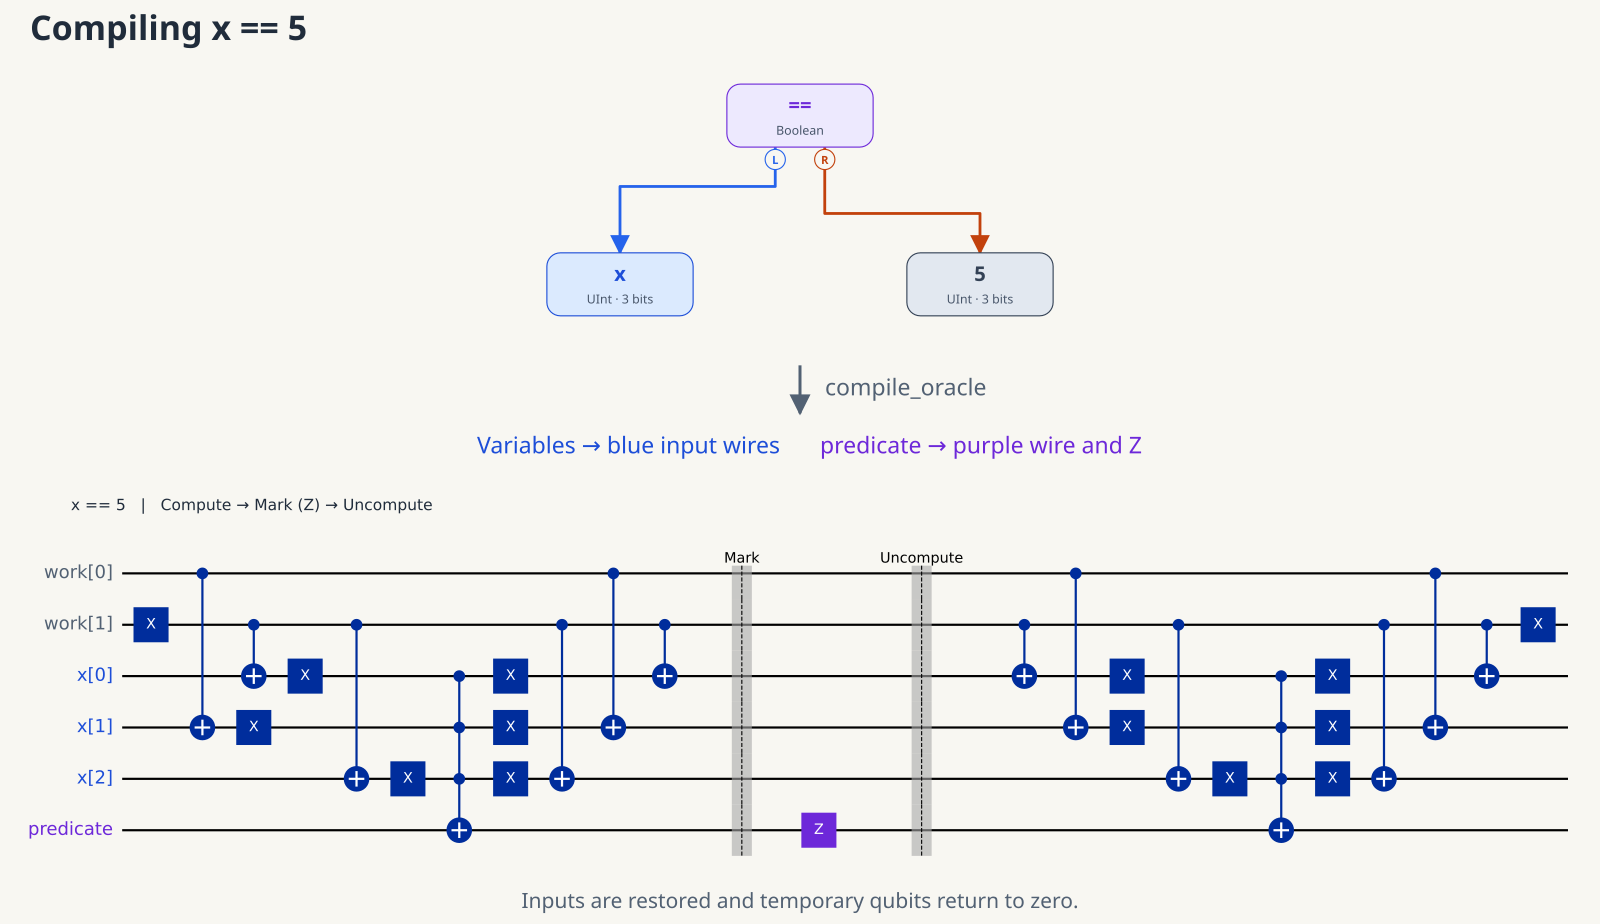

In [7]:
x, y = fresh_variables()
predicate = x == 5
oracle = compile_oracle(predicate)

# The graph and circuit come from the same predicate, compiled once.
show_oracle(predicate, oracle)


### What did the oracle change?

Each bar shows the phase sign of one basis component. Only `x = 5` changes from +1 to −1. These signs describe relative phases in a superposition, not measurement probabilities. The helper also verifies that every input is restored and all workspace returns to zero.


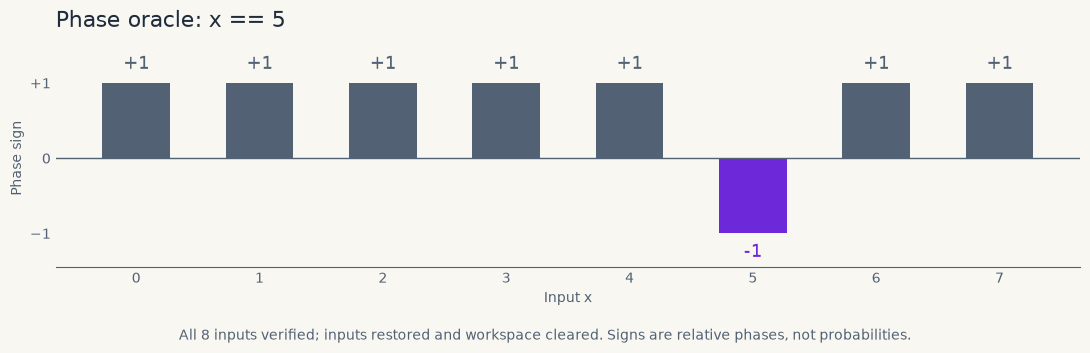

In [8]:
plot_oracle_phases(predicate, oracle);


### Export for the slides

Reuse the figures above as SVG and PNG assets, with the same background as the expression explorer. `oracle-overview.html` places the existing expression graph next to the annotated circuit. Exports are written to the notebook's `oracle_exports` folder.


In [9]:
exported = export_oracle_visuals(predicate, oracle, Path("oracle_exports"), stem="x-equals-5")
for name, path in exported.items():
    print(f"{name}: {path}")


expression_svg: /Users/Swang/Workspace/qlang/examples/oracle_exports/x-equals-5-expression.svg
circuit_png: /Users/Swang/Workspace/qlang/examples/oracle_exports/x-equals-5-circuit.png
circuit_svg: /Users/Swang/Workspace/qlang/examples/oracle_exports/x-equals-5-circuit.svg
overview_svg: /Users/Swang/Workspace/qlang/examples/oracle_exports/x-equals-5-overview.svg
overview_html: /Users/Swang/Workspace/qlang/examples/oracle_exports/x-equals-5-overview.html
phases_png: /Users/Swang/Workspace/qlang/examples/oracle_exports/x-equals-5-phases.png
phases_svg: /Users/Swang/Workspace/qlang/examples/oracle_exports/x-equals-5-phases.svg


Bigger expressions need more qubits and gates.

In [10]:
x, y = fresh_variables()

for label, pred in [("x == 5", x == 5), ("x + y == 5", x + y == 5), ("3 * x + y == 5", 3 * x + y == 5)]:
    circuit = compile_oracle(pred).circuit
    print(f"{label:16} {circuit.num_qubits:3} qubits {circuit.size():4} gates")

x == 5             6 qubits   29 gates
x + y == 5        10 qubits   67 gates
3 * x + y == 5    22 qubits  163 gates


## 7. Oracle truth table

Now return to `x + y == 5`, the same predicate used in the classical check and Grover demonstration. The same compiler handles the arithmetic before marking solutions. We verify all 32 assignments, including restored inputs and zeroed workspace. A sign of `-1` means marked.


In [11]:
x, y = fresh_variables()

print_truth_table(x + y == 5)

 x  y  classical  oracle sign
 2  3  True       -1
 3  2  True       -1
 4  1  True       -1
 5  0  True       -1

32 of 32 inputs match (only solutions are listed); workspace returns to zero


## 8. Grover search

`search` runs the circuit and returns one solution. Measurement is random, so the answer can change between runs, but each one is valid.

In [12]:
x, y = fresh_variables()
pred = x + y == 5

for _ in range(5):
    result = search(PARAMS, pred)
    print(result, "valid:", bool(evaluate(pred, result)))

{'x': 2, 'y': 3} valid: True
{'x': 5, 'y': 0} valid: True
{'x': 3, 'y': 2} valid: True
{'x': 5, 'y': 0} valid: True
{'x': 4, 'y': 1} valid: True


## 9. Amplification

Grover makes solutions more likely with each iteration. `k` is the number of iterations. At `k = 0` every input is equally likely, then the solutions rise above the rest.

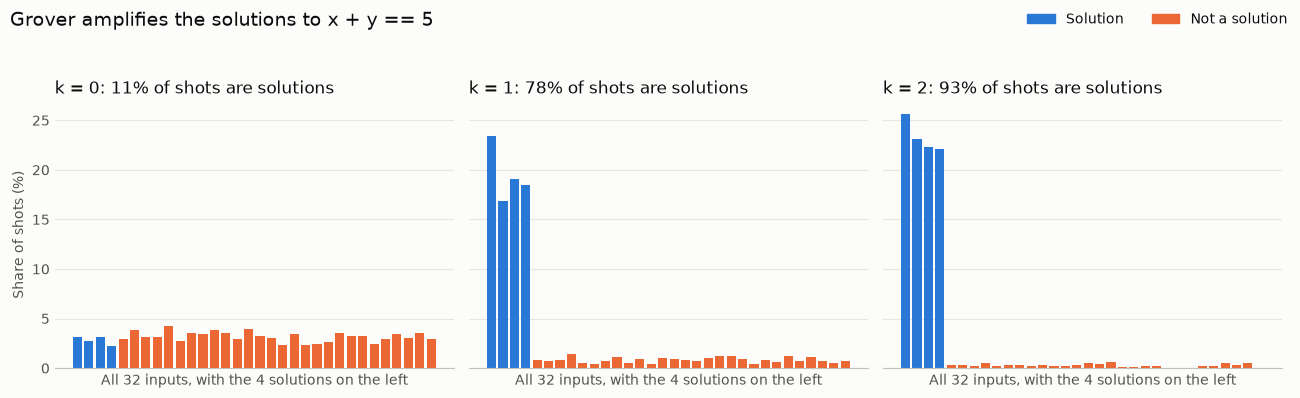

In [13]:
x, y = fresh_variables()

plot_amplification(x + y == 5, "Grover amplifies the solutions to x + y == 5")

## 10. BBHT

The best `k` depends on how many solutions exist, which we don't know in advance. BBHT picks a random `k` under a limit that grows each round, and stops at the first solution.

With one solution, it finds the answer quickly.

In [14]:
x, y = fresh_variables()

traced_search(x + y == 10)

round  1  limit 1.00  k = 1  total iterations  1  found: {'x': 7, 'y': 3}


{'x': 7, 'y': 3}

With no solution, the limit keeps growing until the budget runs out. The largest possible sum is 7 + 3 = 10, so `x + y == 11` can't be satisfied.

In [15]:
x, y = fresh_variables()

traced_search(x + y == 11)

round  1  limit 1.00  k = 1  total iterations  1  found: None
round  2  limit 1.20  k = 1  total iterations  2  found: None
round  3  limit 1.44  k = 2  total iterations  4  found: None
round  4  limit 1.73  k = 2  total iterations  6  found: None
round  5  limit 2.07  k = 1  total iterations  7  found: None
round  6  limit 2.49  k = 3  total iterations 10  found: None
round  7  limit 2.99  k = 1  total iterations 11  found: None
round  8  limit 3.58  k = 3  total iterations 14  found: None
round  9  limit 4.30  k = 2  total iterations 16  found: None
round 10  limit 5.16  k = 2  total iterations 18  found: None
round 11  limit 5.66  k = 5  total iterations 23  found: None
round 12  limit 5.66  k = 4  total iterations 27  found: None
round 13  limit 5.66  k = 1  total iterations 28  found: None
round 14  limit 5.66  k = 1  total iterations 29  found: None
round 15  limit 5.66  k = 1  total iterations 30  found: None
round 16  limit 5.66  k = 1  total iterations 31  found: None
round 17

## 11. QAOA search (need more stuff)

The same expressions work with a second algorithm. QAOA handles optimization: among the inputs that satisfy a constraint, it looks for one with a low objective value.

Here the constraint is `x + y == 3`, and the objective is to make `x` as small as possible.

In [16]:
x, y = fresh_variables()

qaoa([x, y], x + y == 3, objective=x, penalty=4.0, iterations=8)

{'x': 0, 'y': 3}